# Quantile Spatial Regression with Partial Differential Equation Regularization

Alessandro Palummo @ fdaPDE Team, MOX, Department of Mathematics, Politecnico di Milano, Italy

`fdaPDE` (Palummo et al., 2025) is a C++ library with an interface to R for *physics-informed spatial and functional data analysis*, at the intersection of statistics and numerical analysis. The library provides advanced statistical methods designed for data located over complex spatial domains, ranging from irregular planar regions and curved surfaces to linear networks and volumes, possibly evolving over time. The class of methods implemented in `fdaPDE` features regularization terms based on Partial Differential Equations (PDEs), which allow incorporating information derived from the physics of the problem under study into the statistical modeling. This makes `fdaPDE` an extremely flexible tool for the analysis of complex data. For a review of this class of methods, refer to @sangalli2021spatial.

`fdaPDE` offers a wide range of modeling capabilities -- including regression, nonparametric density estimation, functional data analysis, and more -- for data located over a spatial domain, possibly evolving over time. Among the broad range of modeling capabilities offered by `fdaPDE`, we focus here on the **quantile spatial regression method**.

## Nonparametric model

Regression analysis is a widely used tool for studying how a response variable behaves conditionally on a set of covariates. However, when data substantially deviate from the Gaussian assumption -- a scenario frequently encountered in real-world applications -- the conditional mean may be uninformative and provide limited insight. Quantile regression models overcome this limitation by offering a flexible framework to analyze the entire conditional distribution, particularly the tail characteristics of the response variable.

To estimate spatial quantile fields for complex spatial phenomena, we refer to the method introduced in @castiglione2025pde. The proposed model is particularly effective when the data exhibit skewness, heteroscedasticity, or extreme values -- especially when these characteristics vary across space due to physical factors such as wind streams or water currents. The method combines the quantile regression framework with spatial smoothing driven by Partial Differential Equations (PDEs).

Given a real-valued random variable $Y\,,$ we consider $n$ realizations $\left\{y_i\right\}_{i=1}^n \subset \mathbb{R}\,,$ each observed at specific spatial locations $\left\{\mathbf{p}_i\right\}_{i=1}^n \subset \mathcal{D}\,,$ where $\mathcal{D} \subset \mathbb{R}^d\,,$ for $d\geq1\,,$ denotes the *spatial domain* under consideration. Our aim is to estimate the corresponding unknown $\alpha-$*quantile function* $f_\alpha : \mathcal{D} \to \mathbb{R}\,,$ for any probability level $\alpha \in (0,1)\,.$ The **nonparametric spatial regression** model for the $\alpha-$quantile reads as:
$$Q_{Y_i|\mathbf{p}_i}(\alpha) = f_\alpha(\mathbf{p}_i)\,,  \quad \quad i=1,...,n\,. $$
We estimate the unknown quantile spatial field $f_\alpha$ by minimizing the **penalized loss functional**:
$$  J_\alpha(f) = \frac{1}{n} \sum_{i=1}^n \rho_{\alpha}(y_i - f(\mathbf{p}_i)  ) \ + \lambda \int_\mathcal{D} (Lf(\mathbf{p}) - u(\mathbf{p}))^2 \, d\mathbf{p} \,,$$

which balances a *data fidelity* term, expressed by the **pinball loss function** $\rho_\alpha(t) = \frac{1}{2}|t|-(\frac{1}{2}-\alpha)t\,,$ with a **regularization term** based on a problem-specific PDE. The trade-off between these two terms is controlled by the **smoothing parameter** $\lambda\,.$ The optimal value of the smoothing parameter is selected via **Generalized Cross-Validation** (GCV) minimization.

Estimation is performed using the **Expectation-Maximization** (EM) algorithm. Then, the resulting infinite-dimensional solution is discretized through **Finite Element Method** (FEM) over a computational mesh that approximates the spatial domain $\mathcal{D}\,.$ FEM ensures computational efficiency and enables accurate analysis of data scattered over irregularly shaped domains.

## Semiparametric model

The considered modeling framework can be easily generalized to include spatial covariates, thus obtaining a semiparametric version of the previous model. Let $\left\{\mathbf{x}_i\right\}_{i=1}^n \subset \mathbb{R}^q$ be a vector of $q$ spatial covariates measured at the locations $\left\{\mathbf{p}_i\right\}_{i=1}^n\,.$ The **semiparametric spatial regression model** for the $\alpha-$quantile reads as:
$$Q_{Y_i|\mathbf{x}_i, \mathbf{p}_i}(\alpha) = \mathbf{x}_i^\top \boldsymbol{\beta}_\alpha + f_\alpha(\mathbf{p}_i)\,, \quad \quad i=1,...,n\,.$$

We can now jointly estimate the unknown vector of *coefficients* $\boldsymbol{\beta}_\alpha$ and the *quantile spatial field* $f_\alpha\,.$ To do so, we include the parametric term into the data fidelity criterion of the **penalized loss functional** as follows:
$$  J_\alpha(f) = \frac{1}{n} \sum_{i=1}^n \rho_{\alpha}(y_i - \mathbf{x}_i^\top \boldsymbol{\beta}- f(\mathbf{p}_i)  ) \ + \lambda \int_\mathcal{D} (Lf(\mathbf{p}) - u(\mathbf{p}))^2 \, d\mathbf{p}\,.$$

Finally, the estimation and discretization procedures follow the same steps as in the nonparametric model.

The method for Quantile Spatial Regression with Partial Differential Equation regularization presented in this vignette, hereafter referred to as `QSR-PDE`, is implemented within the newest version `fdaPDE` C++ library (Palummo et al., 2025). We load the library in the working environment as follows:

In [1]:
# Import the fdaPDE library
suppressPackageStartupMessages(library(fdaPDE2))  # v. 2.0 (2025)
rm(list = ls())

# Load additional libraries and helper functions for plotting
source("../utils/graphics.R")

In [2]:
theme_set(theme_minimal() +
  theme(
    axis.title = element_text(),
    axis.text = element_text(),
    axis.ticks = element_line(),
    panel.grid = element_line()
  )
)

## Application to Switzerland rainfall data

As a benchmark application in enviornmental sciences, we analyze the **Switzerland rainfall dataset**, which collects $462$ rainfall measurements (in $10 \, \mu m$ units) recorded on May 8, 1986. This dataset is well known in the statistical community, with several studies dedicated to its analysis, including @dubois2003mapping and @dubois2007automatic. Starting from this set of georeferenced data, the goal is to estimate spatial quantile maps of the rainfall distribution. To compare the median tendency of the phenomenon with tail behavior, we focus on the estimates for both $50\%$ and $90\%$ quantile fields, assessing whether some regions are more prone to experience extreme values and to identify potential spatial patterns associated with high-risk events.

### 1. Spatial domain

First, we load the boundary nodes of our domain of interest, which are stored sequentially in a clockwise order. We then construct the matrix of boundary segments, with each row containing the indices of the boundary nodes that define a segment.

In [3]:
## [SPATIAL DOMAIN]
# Load the boundary nodes
boundary_nodes <- read.table(file = "../../data/QSRPDE_2D/boundary_coords.txt", header = FALSE)
names(boundary_nodes) <- c("lon", "lat")

# Create boundary segments (consecutive boundary nodes are connected)
boundary_segments <- cbind(1:(nrow(boundary_nodes)-1), 2:nrow(boundary_nodes))

# Close the loop (connect the last node to the first)
boundary_segments <- rbind(boundary_segments, c(nrow(boundary_nodes), 1))

The domain can be interactively visualized using the `mapview` [@appelhans2025mapview] R package, once boundary nodes are converted into a `sf` [@pebesma2025sf] object.

In [4]:
# Convert boundary into a sf object
boundary_nodes_sf <- st_as_sf(x = rbind(boundary_nodes, boundary_nodes[1,]), coords = c("lon", "lat"), crs = 4326)
boundary_polygon  <- st_polygon(list(st_coordinates(boundary_nodes_sf)))
boundary_sfc      <- st_sfc(geometry = boundary_polygon, crs = 4326)
boundary_sf       <- st_sf(geometry = boundary_sfc)

# Interactive plot
display_map(
    mapview(boundary_sf,
        col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
        legend = FALSE, layer.name = "domain")
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 1: Spatial domain of interest – Switzerland.
</div>

Now we build a **regular mesh** of the spatial domain under consideration. We create a mesh based on boundary nodes and segments, and then we refine it by setting the maximum element area to $0.0045$ and the minimum angle to 30 degrees. The triangulation is constructed using the `RTriangle` [@shewchuk2025RTriangle] R package. Other software can be used to get the triangulation; for example, it can be constructed through the `fmesher` [@lindgren2025fmesher] R package.

In [5]:
# Define a planar straight-line graph object
p <- pslg(P = boundary_nodes, S = boundary_segments)

# Create a regular mesh of the spatial domain
mesh <- triangulate(p = p, Y = FALSE, D = TRUE)
if (is.null(mesh$H)) mesh$H <- matrix(numeric(0), ncol = 2)

# Refine the mesh of the spatial domain
mesh <- triangulate(mesh, a = 0.0045, q = 30, D = TRUE)

We convert the `triangulation` object from RTriangle so that it can be read by `fdaPDE`.

In [6]:
# Set up the triangulation for fdaPDE
mesh = triangulation(nodes = mesh$P, cells = mesh$T, boundary = mesh$PB)

We visualize the resulting mesh of the spatial domain of interest.

In [7]:
# Interactive plot
display_map(
    mapview(boundary_sf,
        col.regions = "gray25", alpha.regions = 0.25, col = "black", lwd = 1.5,
        legend = FALSE, layer = "domain") +
    mapview(mesh, crs = 4326,
          col.regions = "transparent", lwd = 1.25, legend = FALSE, layer = "mesh")
)

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 2: Regular mesh of the Switzerland domain with $1\,128$ nodes and $2\,077$ triangles.
</div>

We use the triangulation just created to define the spatial support of a `geoframe` object. This object will host layers containing data observed over the spatial support.

In [8]:
switzerland <- geoframe(domain = mesh)

### 2. Data

We import the preprocessed data from the file `../../data/QSRPDE_2D/locations.txt and log_rainfall.txt` as a `data.frame` object. We add a data layer to the geoframe object defined above, thus obtaining a format compatible with the implementation of the proposed regression method.

In [9]:
## [DATA]
# Load the data
locations <- read.table("../../data/QSRPDE_2D/locations.txt")
log_rainfall <- scan("../../data/QSRPDE_2D/log_rainfall.txt")
data <- data.frame(
    lon          = locations[[1]], 
    lat          = locations[[2]],
    rainfall     = exp(log_rainfall), 
    log.rainfall = log_rainfall
)

# Add layer with data to the geoframe object
switzerland$insert(layer = "rainfall", type = "point", geo = c("lon", "lat"), data = data)
switzerland

Geoframe with 1 layers
Bounding box:    xmin: 5.909523 ymin: 45.79278 xmax: 10.58403 ymax: 47.8322
Number of nodes: 1118
Number of cells: 2060

Layer: rainfall
Type:  POINT
Dims: 462, 2
First 6 data rows:
rainfall log.rainfall 
<flt64>  <flt64>      
1.84     0.609766     
1.21     0.19062      
1.38     0.322083     
1.26     0.231112     
1.56     0.444686     
1        0            

To visualize the rainfall distribution, we plot the data across the Switzerland region in both the original and logarithmic scales.

In [10]:
map1 <- mapview(switzerland[["rainfall"]], 
          varnames = "rainfall", crs = 4326,
          color_palettes = list("mako"), na.color = "transparent",
          layer.name = "rainfall") +
        mapview(boundary_sf, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map2 <- mapview(switzerland[["rainfall"]], 
          crs = 4326, varnames = "log.rainfall",
          color_palettes = list("mako"), na.color = "transparent",
          layer.name = "log.rainfall") +
        mapview(boundary_sf, 
          col.regions = "transparent", alpha.regions = 0,
          col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map1, map2))

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="

<div style="text-align: center;">
Figure 3: Switzerland rainfall data collected at $462$ locations, shown in the original scale (left) and in logarithmic scale (right).
</div>

### 3. QSR-PDE model fitting for physics-informed smoothing

The data exhibit strong anisotropic patterns across the domain. To account for the clear anisotropy observed in the data, we incorporate a stationary anisotropic diffusion term into the model. To do so, we define the differential operator as
$$Lf(\mathbf{p}) = \text{div}(\mathbf{K}\nabla f(\mathbf{p})) \quad \forall \mathbf{p} \in \mathcal{D}\,.$$
The anisotropy tensor $\mathbf{K}$ is estimated using the **parameter cascading algorithm** presented in @bernardi2018modeling, yielding an orientation angle of $140^\circ (2.45 \ \text{rad})$ and an intensity of anisotropy of $6.00\,.$

In [11]:
## [DIFFUSION TENSOR]
K <- matrix(
    c(1.229618413471819, 1.001009926596135, 1.001009926596135, 1.628164356689574),
    nrow = 2, ncol = 2, byrow = TRUE
)

#### 3.1 Physics-informed smoothing for the 50\% quantile level

We can now compute the physics-informed quantile spatial estimate, for the $50\%$ probability level. To this end, we use the `qsr` function, setting the quantile level with the option `level = 0.5` and providing the anistropic diffusion tensor with `fe_elliptic(K = K)` as a penalty descriptor. The actual fitting is obtained by calling the `fit` method of the class `qsr`. The optimal smoothing parameter $\lambda$ is selected via Generalized Cross-Validation (GCV) minimization using grid search method.

In [12]:
## [PHYSICS-INFORMED QUANTILE REGRESSION]
# Set up the finite element function (order 1)
f <- fe_function(mesh, type = "P1")

# Proposed value for the smoothing parameter
lambda_grid = 10^seq(from = -7, to = -3, by = 0.2)

# Physics informed smoothing model
m <- qsr(log.rainfall ~ f, data = switzerland, level = 0.5, penalty = fe_elliptic(K = K))

# Physics informed smoothing fit with grid search for GCV minimization
fit = m$fit(
  calibrator = gcv(optimizer = grid_search(grid = lambda_grid), seed = 425)
)

Moreover, it is possible to inspect the behavior of the GCV indices as a function of the values proposed for the smoothing parameter $\lambda\,.$

Optimal lambda value: 1e-05

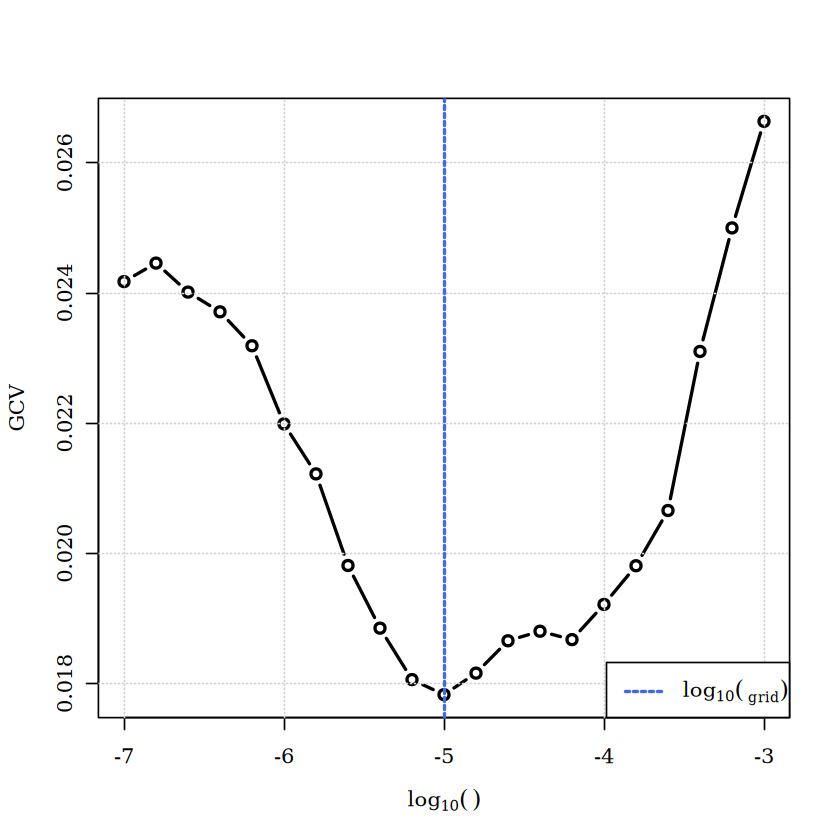

In [14]:
# GCV indices
gcv <- fit$values  

# Optimal value selected for the smoothing parameter
lambda_opt_grid <- fit$optimum
cat("Optimal lambda value:", lambda_opt_grid)

# Plot of the GCV curve
par(family = "serif")
plot(x = log10(lambda_grid), y = gcv, type = "b",
     lwd = 2, xlab = TeX("$\\log_{10}(\\lambda)$"), ylab = "GCV")
grid()
abline(v = log10(lambda_opt_grid), lty = 2, lwd = 2, col = "royalblue")
legend("bottomright", lty = 2, lwd = 2, col = "royalblue",
       legend = TeX("$\\log_{10}(\\lambda_{grid})"))

<div style="text-align: center;">
Figure 4: GCV curve for the $50\%$ quantile field.
</div>

The GCV curve is convex with minimum realized at the optimal value selected by the method -- specifically $1e-5\,.$.

We visualize the $50\%$ quantile estimate computed above in the logarithmic scale using `mapview`. In addition, we visualize the $50\%$ quantile estimate in the original scale, applying the `fit` function to the `fe_function` object.

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
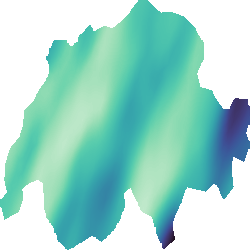
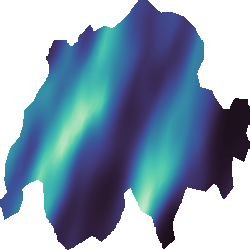

In [15]:
# Interactive plot
map_log50 <- mapview(f, 
               crs = 4326, col.regions = mako,
               na.color = "transparent", layer.name = "log.rainfall") +
             mapview(boundary_sf, 
               col.regions = "transparent", alpha.regions = 0,
               col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map_50 <- mapview(exp(f), 
            crs = 4326, col.regions = mako,
            na.color = "transparent", layer.name = "rainfall") +
          mapview(boundary_sf, 
            col.regions = "transparent", alpha.regions = 0,
            col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map_log50, map_50))

<div style="text-align: center;">
Figure 5: Rainfall $50\%$ quantile estimate in the logarithmic scale computed by the physics-informed `QSR-PDE` with optimal lambda $1e-05$ selected via GCV minimization using grid search method (left); rainfall $50\%$ quantile estimate in the original scale computed by the physics-informed `QSR-PDE` with optimal lambda $1e-05$ selected via GCV minimization using grid search method (right).
</div>

#### 3.2 Physics-informed smoothing for the 90\% quantile level

We repeat the analysis for the quantile level $\alpha = 90\%$ and we compare the two fitted quantile fields.

In [16]:
## [PHYSICS-INFORMED QUANTILE REGRESSION]
# Set up the finite element function (order 1)
f <- fe_function(mesh, type = "P1")

# Proposed value for the smoothing parameter
lambda_grid = 10^seq(from = -7, to = -4, by = 0.2)

# Physics informed smoothing model
m <- qsr(log.rainfall ~ f, data = switzerland, level = 0.9, penalty = fe_elliptic(K = K))

# Physics informed smoothing fit with grid search for GCV minimization
fit = m$fit(
  calibrator = gcv(optimizer = grid_search(grid = lambda_grid), seed = 425)
)

We inspect the behavior of the GCV indices as a function of the values proposed for the smoothing parameter $\lambda\,.$

Optimal lambda value: 2.511886e-06

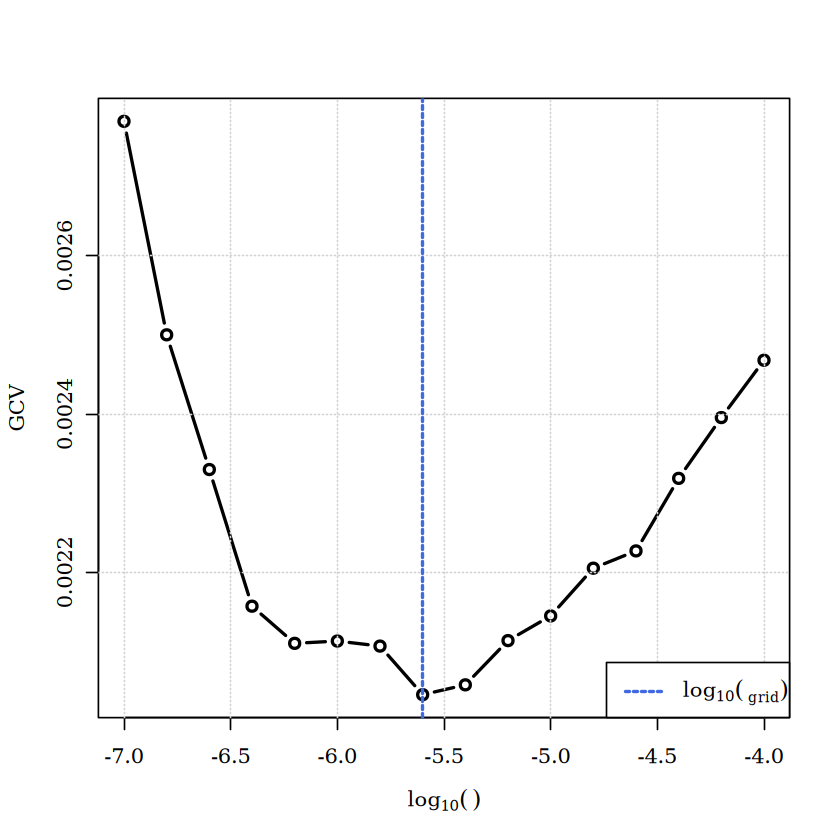

In [17]:
# GCV indices
gcv <- fit$values  

# Optimal value selected for the smoothing parameter
lambda_opt_grid <- fit$optimum
cat("Optimal lambda value:", lambda_opt_grid)

# Plot of the GCV curve
par(family = "serif")
plot(x = log10(lambda_grid), y = gcv, type = "b",
     lwd = 2, xlab = TeX("$\\log_{10}(\\lambda)$"), ylab = "GCV")
grid()
abline(v = log10(lambda_opt_grid), lty = 2, lwd = 2, col = "royalblue")
legend("bottomright", lty = 2, lwd = 2, col = "royalblue",
       legend = TeX("$\\log_{10}(\\lambda_{grid})"))

<div style="text-align: center;">
Figure 6: GCV curve for the $90\%$ quantile field.
</div>

Also in this case, the GCV curve is convex with minimum realized at the optimal value selected by the method, specifically $2.511886e-06\,.$.

We visualize the $90\%$ quantile estimate computed above in both the logarithmic and original scales.

<iframe srcdoc="<!doctype html>
<html>
	<head>
 <meta charset="utf-8">
 <script title="htmlwidgets" src="..."></script>
<script title="jquery" src="..."></script>
<script title="leaflet" src="..."></script>
<link href="
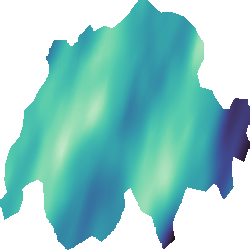
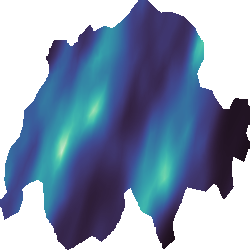

In [18]:
# Interactive plot
map_log90 <- mapview(f, 
               crs = 4326, col.regions = mako,
               na.color = "transparent", layer.name = "log.rainfall") +
         mapview(boundary_sf, 
           col.regions = "transparent", alpha.regions = 0,
           col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

map_90 <- mapview(exp(f), 
            crs = 4326, col.regions = mako,
            na.color = "transparent", layer.name = "rainfall") +
          mapview(boundary_sf, 
            col.regions = "transparent", alpha.regions = 0,
            col = "black", lwd = 1.5, layer.name = "domain", legend = FALSE)

display_map(sync(map_log90, map_90))

<div style="text-align: center;">
Figure 7: Rainfall $90\%$ quantile estimate in the logarithmic scale computed by the physics-informed `QSR-PDE` with optimal lambda $2.5e-06$ selected via GCV minimization using grid search method (left); rainfall $90\%$ quantile estimate in the original scale computed by the physics-informed `QSR-PDE` with optimal lambda $2.5e-06$ selected via GCV minimization using grid search method (right).
</div>

Comparing the two estimated quantile fields, we observe that the median surface appears considerably smoother than the $90\%$ quantile. This is expected, as the median is more robustness to skewness and local outliers. On the other hand, the $90\%$ quantile surface exhibits several pronounced local spikes, highlighting regions prone to extreme precipitation. These peaks suggest that certain areas experience significantly higher rainfall extreme events, highlighting the importance of analyzing the upper-tail quantiles when assessing rainfall risk.

## References

<div id="refs" class="references csl-bib-body hanging-indent"
data-entry-spacing="0" data-line-spacing="2" role="list">
<div id="ref-appelhans2025mapview" class="csl-entry" role="listitem">
Appelhans, T., Detsch, F., Reudenbach, C., &amp; Woellauer, S. (2023).
<em>Mapview: <span>I</span>nteractive viewing of spatial data in
<span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=mapview"
class="uri">https://CRAN.R-project.org/package=mapview</a>.
</div>
<div id="ref-bernardi2018modeling" class="csl-entry" role="listitem">
Bernardi, M. S., Carey, M., Ramsay, J. O., &amp; Sangalli, L. M. (2018).
Modeling spatial anisotropy via regression with partial differential
regularization. <em>Journal of Multivariate Analysis</em>, <em>167</em>,
15–30. <a
href="https://doi.org/10.1016/j.jmva.2018.03.014">https://doi.org/10.1016/j.jmva.2018.03.014</a>
</div>
<div id="ref-castiglione2025pde" class="csl-entry" role="listitem">
Castiglione, C., Arnone, E., Bernardi, M., Farcomeni, A., &amp;
Sangalli, L. M. (2025). PDE-regularised spatial quantile regression.
<em>Journal of Multivariate Analysis</em>, <em>205</em>. <a
href="https://doi.org/10.1016/j.jmva.2024.105381">https://doi.org/10.1016/j.jmva.2024.105381</a>
</div>
<div id="ref-dubois2003mapping" class="csl-entry" role="listitem">
Dubois, G., Malczewski, J., &amp; De Cort, M. J. M. R. (2003).
<em>Mapping radioactivity in the environment. Spatial interpolation
comparison 97</em>. European Commission.
</div>
<div id="ref-dubois2007automatic" class="csl-entry" role="listitem">
Dubois, G., Pebesma, E. J., &amp; Bossew, P. (2007). Automatic mapping
in emergency: A geostatistical perspective. <em>International Journal of
Emergency Management</em>, <em>4</em>(3), 455–467.
</div>
<div id="ref-lindgren2025fmesher" class="csl-entry" role="listitem">
Lindgren, F. (2025). <em>Fmesher: <span>T</span>riangle meshes and
related geometry tools</em>. url: <a
href="https://CRAN.R-project.org/package=fmesher"
class="uri">https://CRAN.R-project.org/package=fmesher</a>.
</div>
<div id="ref-palummo2026fdapde" class="csl-entry" role="listitem">
Palummo, A., Clemente, A., Sangalli, E., Arnone, Formaggia, L., &amp;
Maria, L. (2025). <em>fdaPDE: <span>P</span>hysics-informed statistical
learning</em>. url: <a href="https://github.com/fdaPDE/fdaPDE-R"
class="uri">https://github.com/fdaPDE/fdaPDE-R</a>.
</div>
<div id="ref-pebesma2025sf" class="csl-entry" role="listitem">
Pebesma, E. (2025). <em>Sf: <span>S</span>imple <span>F</span>eatures
for <span>R</span></em>. url: <a
href="https://CRAN.R-project.org/package=sf"
class="uri">https://CRAN.R-project.org/package=sf</a>.
</div>
<div id="ref-sangalli2021spatial" class="csl-entry" role="listitem">
Sangalli, L. M. (2021). Spatial regression with partial differential
equation regularisation. <em>International Statistical Review</em>,
<em>89</em>(3), 505–531. <a
href="https://doi.org/10.1111/insr.12444">https://doi.org/10.1111/insr.12444</a>
</div>
<div id="ref-shewchuk2025RTriangle" class="csl-entry" role="listitem">
Shewchuk, J. R., &amp; Sterratt, D. C. (2025). <em>RTriangle - a
2<span>D</span> quality mesh generator and <span>D</span>elaunay
triangulator</em>. url: <a
href="https://CRAN.R-project.org/package=RTriangle"
class="uri">https://CRAN.R-project.org/package=RTriangle</a>.
</div>
</div>